In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

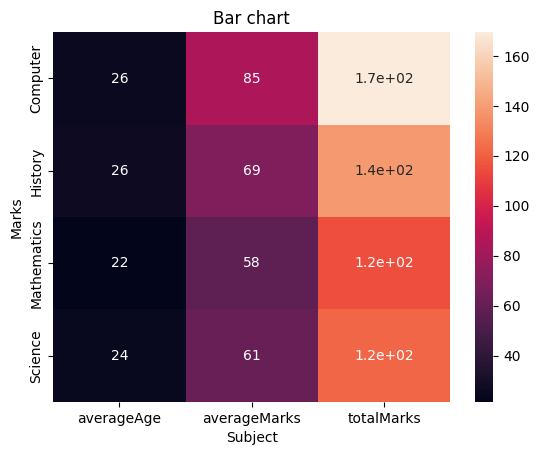

In [49]:
data = {
    'Student_Name': ['Rahul', 'Priya', 'Aman', 'Sneha', 'Vikram', "David", "Alsa", "Jhon"],
    'Age':[20,19,23,25, np.nan, 26,30,28],
    'Subject': ['Mathematics', 'Science', 'Mathematics', 'History', 'Computer', 'Computer', 'Science', 'History'],
    'Marks': [85, 92, 30, 64, 95, np.nan, 30, np.nan]
}

df =  pd.DataFrame(data)
# print(df.isna().sum())

colFill = ["Age", "Marks"]

df[colFill] = df[colFill].fillna(df[colFill].median())

# print(df.isna().sum())

df["Result"] = np.where(df["Marks"] >= 35, "Pass", "Fail")

grading = [
    df["Marks"] >= 90,
    df["Marks"] >= 60,
    df["Marks"] >= 50,
    df["Marks"] >= 35,
]

df["Grade"] = np.select(grading, ["A+", "A", "B", "C"], default="Fail")

# res = df[df["Result"] == "Pass"]
# res = df[df["Grade"] == "A+"]
# res = df[df["Marks"] >= 60]

res = df.groupby("Subject").agg(
    averageAge = ("Age", "mean"),
    averageMarks = ("Marks", "mean"),
    totalMarks = ("Marks", "sum")
).round(1)

# plt.Figure(figsize="8", dpi=500)

# plt.bar(res.index, res["averageAge"])
# plt.pie(res["averageAge"])

# sns.barplot(data=res, x=res["averageAge"], y=res["averageMarks"])
sns.heatmap(data=res, annot=True)

# plt.ylim(0,100)
plt.xlabel("Subject")
plt.ylabel("Marks")
plt.title("Bar chart")

plt.savefig("heatchart.png", dpi=500)

plt.show()